# Stage-1 gate: is this mouth healthy, or does it have an issue? (DenseNet-121 vs DINOv2 ViT-B/14)

**Pipeline.** Every photo goes through this binary classifier first. Only photos it flags go on to the YOLO detector
(stage 2, `models/yolo_caries/scripts/Aiden/`), which says *which* condition and *where*. A photo the gate misses never
reaches YOLO, so the gate is tuned to **catch issues** (threshold = catch 95% of issues on the clean val set).

**Data.** Daniel's `oral_dataset` (`data/raw/oral_dataset/`, from his `qwen_clean_and_label.ipynb`), target `has_issue`,
his train / val / test split.

**This notebook explains and checks; the scripts do the work.** Training is in `scripts/Aiden/train.py`, the comparison
report and graphs in `scripts/Aiden/report.py`. The notebook imports them instead of copying their code, so the two can't
drift apart. Set `RETRAIN = True` to retrain both models from here (about 1-2 h each on an RTX 4060); otherwise it reads
the saved results in `results/Aiden/`.

Sections: 1 setup · 2 the data · 3 leakage · 4 the source problem · 5 training method · 6 results · 7 results per source
· 8 most confident mistakes · 9 Grad-CAM · 10 experiment log and decision

## 1. Setup

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
from IPython.display import Image as Show, Markdown, display

REPO = Path.cwd().resolve()
while not (REPO / "models").is_dir():
    REPO = REPO.parent
sys.path[:0] = [str(REPO / "models/classifier/scripts/Aiden"), str(REPO / "models/classifier/src")]
import train, report, multilabel        # the same code the scripts run
%matplotlib inline

RETRAIN = False                         # True: retrain both models (overwrites results/Aiden/<arch>/)
ARCHS = {"densenet121": "--lr 1e-4", "dinov2_vitb14": ""}   # the learning rates used in the comparison
DATA, RESULTS, TARGET, CONDITIONS = train.DATA, train.RESULTS, train.TARGET, train.CONDITIONS
FIG = RESULTS / "figures"
pd.set_option("display.width", 160)

## 2. The data

In [2]:
df = pd.read_csv(DATA / "labels.csv", keep_default_na=False)
df = df.merge(pd.read_csv(train.LEAKS)[["md5", "leaked"]], on="md5", how="left")
df["leaked"] = df.leaked.fillna(False).astype(bool)
print(f"{len(df)} images, {df.group.nunique()} photo groups (copies of one photo share a group)")
display(pd.crosstab(df.split, df[TARGET].map({0: "healthy", 1: "has an issue"}), margins=True))
print("images with each condition, per split (one image can have several):")
display(df.groupby("split")[CONDITIONS].sum().T[["train", "val", "test"]])

# Has the dataset changed since the saved models were trained?
for arch in ARCHS:
    m = RESULTS / arch / "metrics.json"
    if m.exists():
        n = json.loads(m.read_text())["n_train"]
        same = n == (df.split == "train").sum()
        print(f"{arch}: trained on {n} training images; this labels.csv has {(df.split == 'train').sum()}"
              + ("" if same else "  <-- DIFFERENT: retrain (and re-run find_leaks.py) before trusting section 6"))

37913 images, 20430 photo groups (copies of one photo share a group)


has_issue,has an issue,healthy,All
split,,,
test,2447,963,3410
train,23921,7358,31279
val,2301,923,3224
All,28669,9244,37913


images with each condition, per split (one image can have several):


split,train,val,test
Calculus,3628,429,415
Caries,10749,845,811
Hypodontia,2500,288,397
Mouth_Ulcer,4711,550,568
Tooth_Discoloration,8520,868,885


densenet121: trained on 31279 training images; this labels.csv has 31279
dinov2_vitb14: trained on 31279 training images; this labels.csv has 31279


## 3. Leakage: copies of training photos in val and test

Roboflow's export holds many cropped, rotated and recoloured copies of each photo, and they were spread over train, val
and test. A model can then score well on test by *remembering* photos. `scripts/Aiden/find_leaks.py` marks every val/test
image with a copy in train (DINOv2 proposes similar pairs, SIFT keypoint matching confirms them). Those are left out of
the **clean** val and test sets; the threshold and the headline scores use only the clean sets.

images  copies_of_train  share_leaked
split has_issue                                       
test  0             963                0         0.000
      1            2447             2269         0.927
val   0             923                0         0.000
      1            2301             2089         0.908

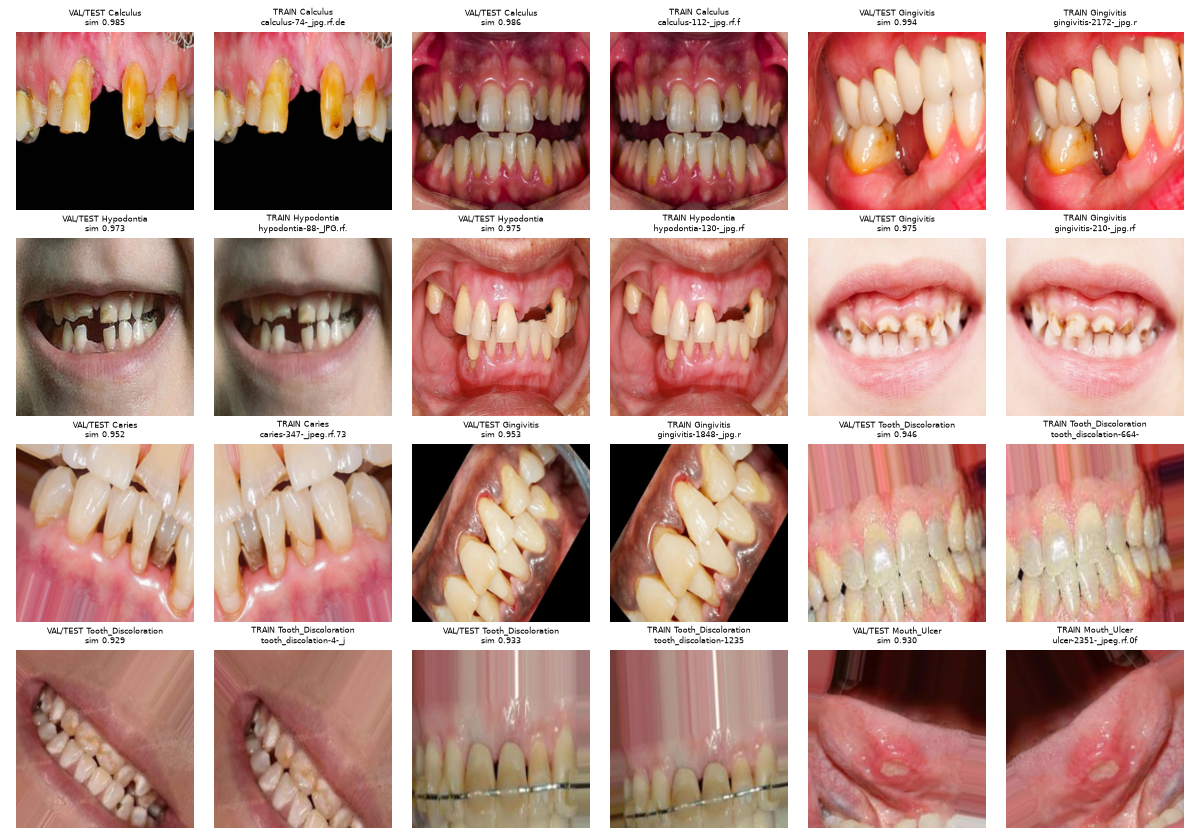

In [3]:
t = df[df.split != "train"].groupby(["split", TARGET]).leaked.agg(images="size", copies_of_train="sum")
t["share_leaked"] = (t.copies_of_train / t.images).round(3)
display(t)
display(Show(FIG / "roboflow_split_leak_pairs.png", width=900))   # examples of matched pairs

## 4. The source problem: what the clean test can and cannot show

The table below is the clean test set by *where each photo came from*. Every image with an issue comes from
`roboflow_oral` and every healthy image from another source. So the clean test can't tell apart a model that recognises
disease from one that recognises "a Roboflow-style photo" (its cropping, colour, resolution, compression): both would
score the same. Training has the same pattern (all Mendeley photos are healthy, all Roboflow photos have an issue).

This is a limitation of the data, not of either model, and it applies to both. Section 7 checks the part we can;
Grad-CAM (section 9) shows whether the models look at teeth or at the background.

In [4]:
clean_test = df[(df.split == "test") & ~df.leaked]
display(pd.crosstab(clean_test.dataset, clean_test[TARGET].map({0: "healthy", 1: "has an issue"}), margins=True))
print("training set:")
display(pd.crosstab(df[df.split == "train"].dataset, df[df.split == "train"][TARGET].map({0: "healthy", 1: "has an issue"})))

has_issue,has an issue,healthy,All
dataset,,,
dentalai,0,94,94
external_clean,0,14,14
kaggle_oral,0,59,59
mendeley_noncaries,0,472,472
roboflow_oral,178,0,178
zenodo,0,324,324
All,178,963,1141


training set:


has_issue,has an issue,healthy
dataset,,
dentalai,1497,738
external_clean,325,109
kaggle_oral,754,121
mendeley_noncaries,0,3636
roboflow_oral,18529,0
zenodo,2816,2754


## 5. Training method (`train.py`)

| Choice | Why |
|---|---|
| DenseNet-121 (ImageNet, 8M params) vs DINOv2 ViT-B/14 (self-supervised, 86M) | a strong CNN baseline against a modern foundation model |
| One sigmoid output, BCE with `pos_weight` | binary target; `pos_weight` balances healthy vs issue |
| Label smoothing 0.05 | some labels come from Qwen and are wrong (section 8 shows examples) |
| Every photo group equally likely per epoch | some photos have 200 copies in train; they would outvote the rest |
| Augmentation: crop, flip, rotate, brightness/contrast; **no hue/saturation** | tooth discolouration *is* a colour |
| AdamW, one-cycle cosine schedule, fixed 10 epochs | no epoch is picked on val, so val stays unbiased for the threshold |
| DINOv2: layer-wise LR decay 0.75 | lower layers hold general features, so they change less |
| Flip test-time augmentation | average of the photo and its mirror image |
| Platt calibration + threshold on clean val | probability means something; threshold = catch 95% of clean-val issues |

In [5]:
if RETRAIN:
    for arch, extra in ARCHS.items():
        cmd = [sys.executable, str(REPO / "models/classifier/scripts/Aiden/train.py"), "--arch", arch, *extra.split()]
        print(" ".join(cmd)); subprocess.run(cmd, check=True, cwd=REPO)
else:
    print("RETRAIN = False: using the saved results in", RESULTS)

RETRAIN = False: using the saved results in C:\Users\aiden\Downloads\AI WIU\Deep-Learning-WIU\models\classifier\results\Aiden


## 6. Results (clean test unless stated)

,DenseNet-121,DINOv2 ViT-B/14
AUROC (95% CI),0.9953 (0.9917-0.9982),0.9925 (0.9872-0.9971)
AP,0.974,0.894
sensitivity (95% CI),0.949 (0.913-0.979),0.944 (0.907-0.976)
specificity,0.989,0.991
issues missed,9 of 178,10 of 178
false alarms,11 of 963,9 of 963
threshold,0.595,0.874
"AUROC, full test (leaky)",0.9959,0.9926
reaches YOLO: Calculus,83% of 6,100% of 6
reaches YOLO: Caries,96% of 23,96% of 23


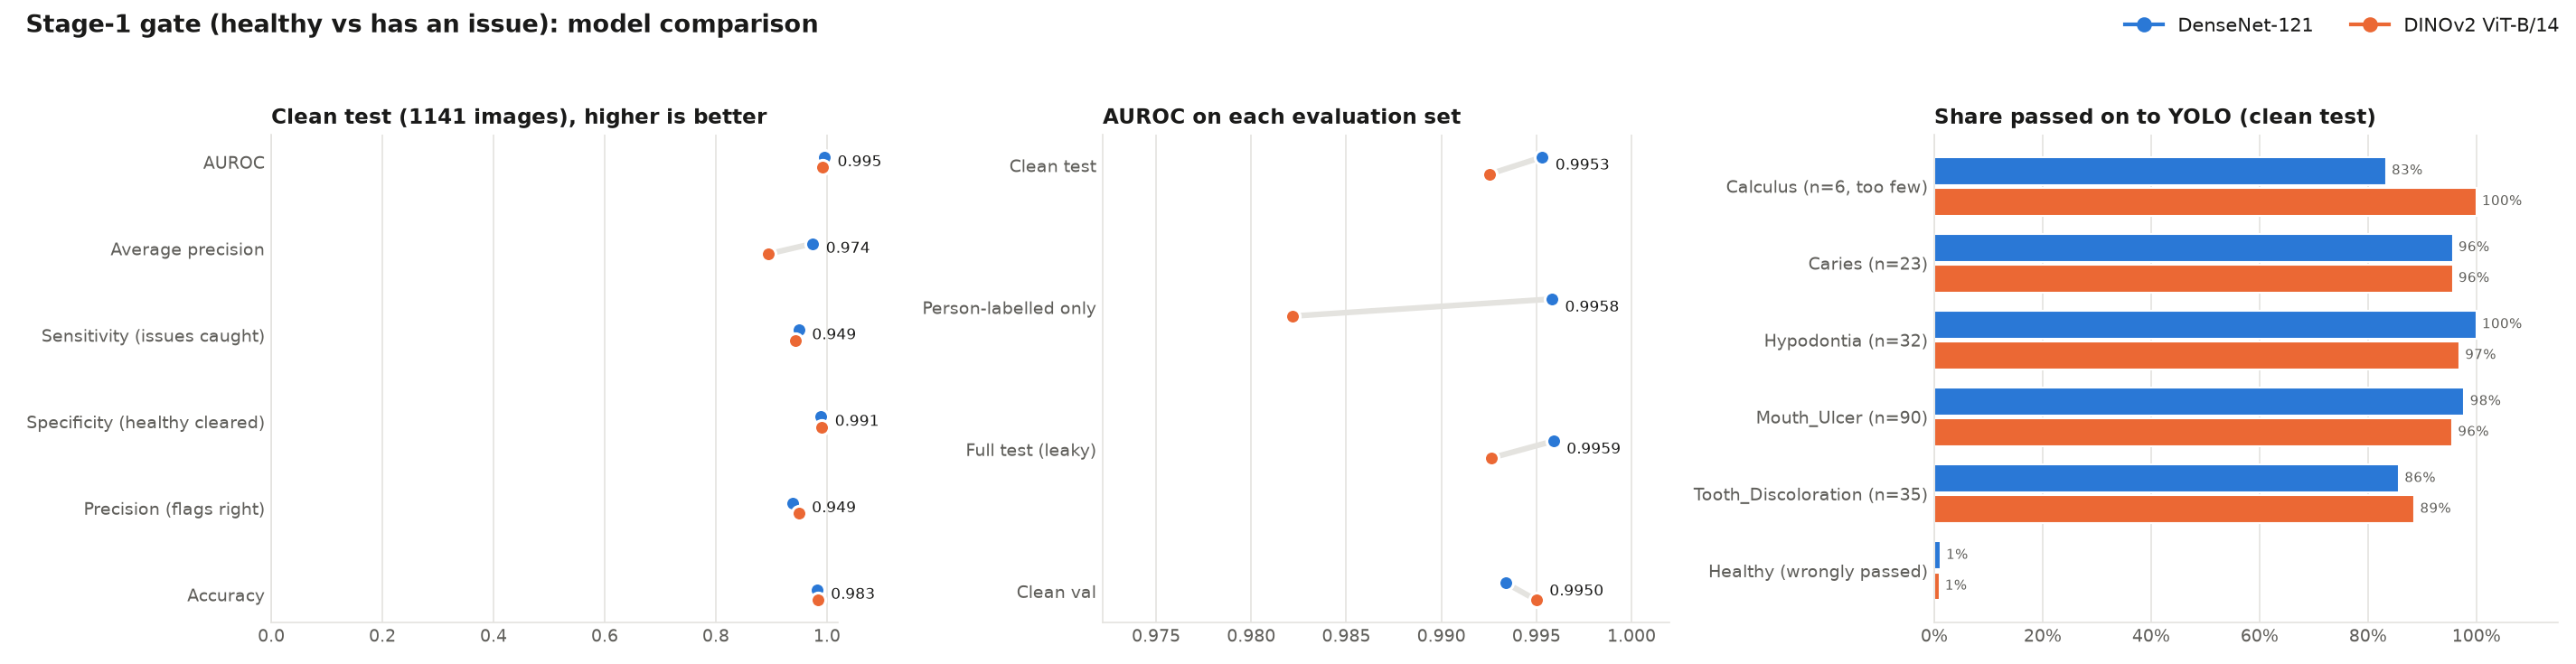

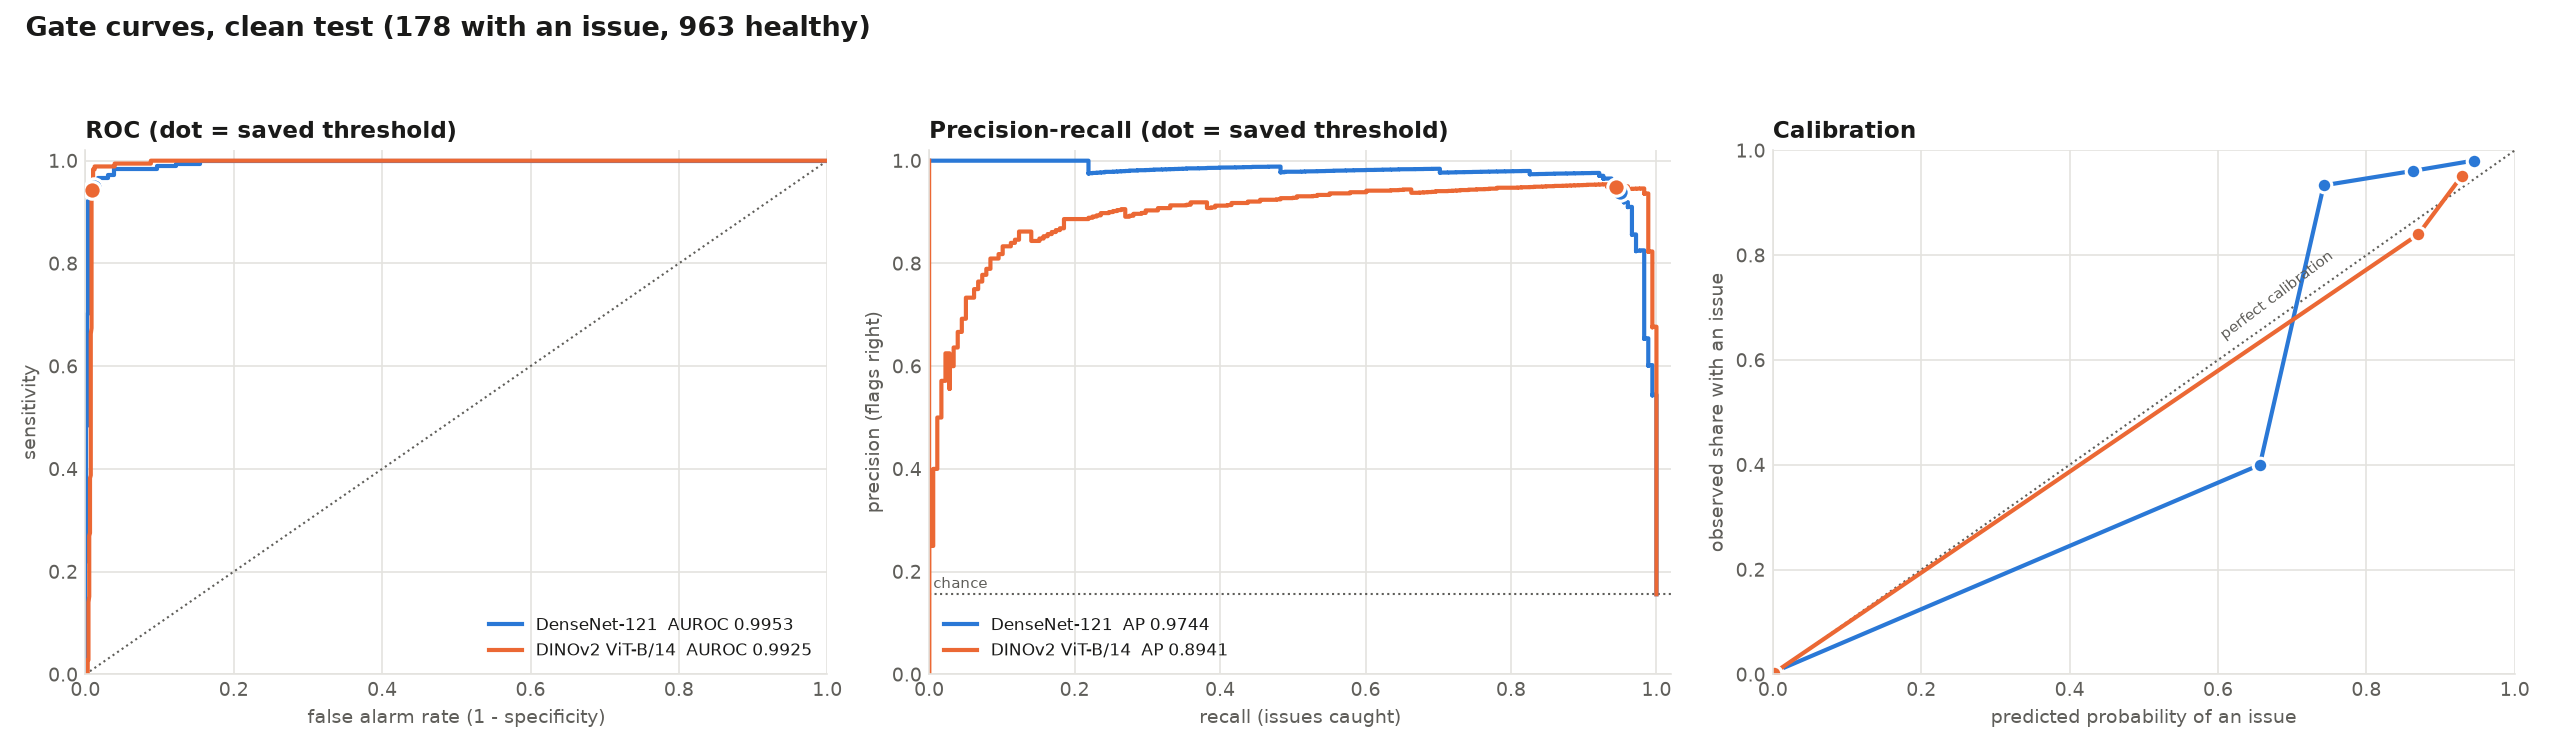

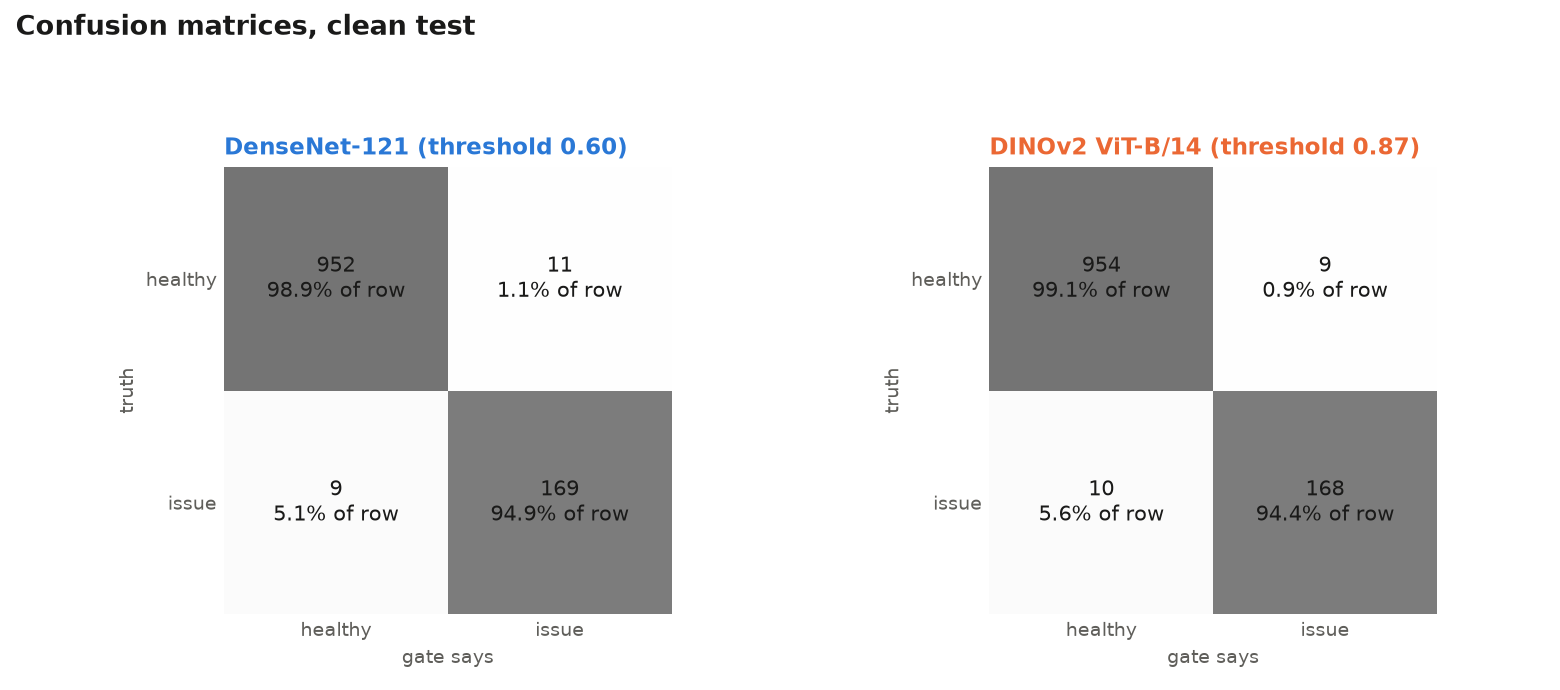

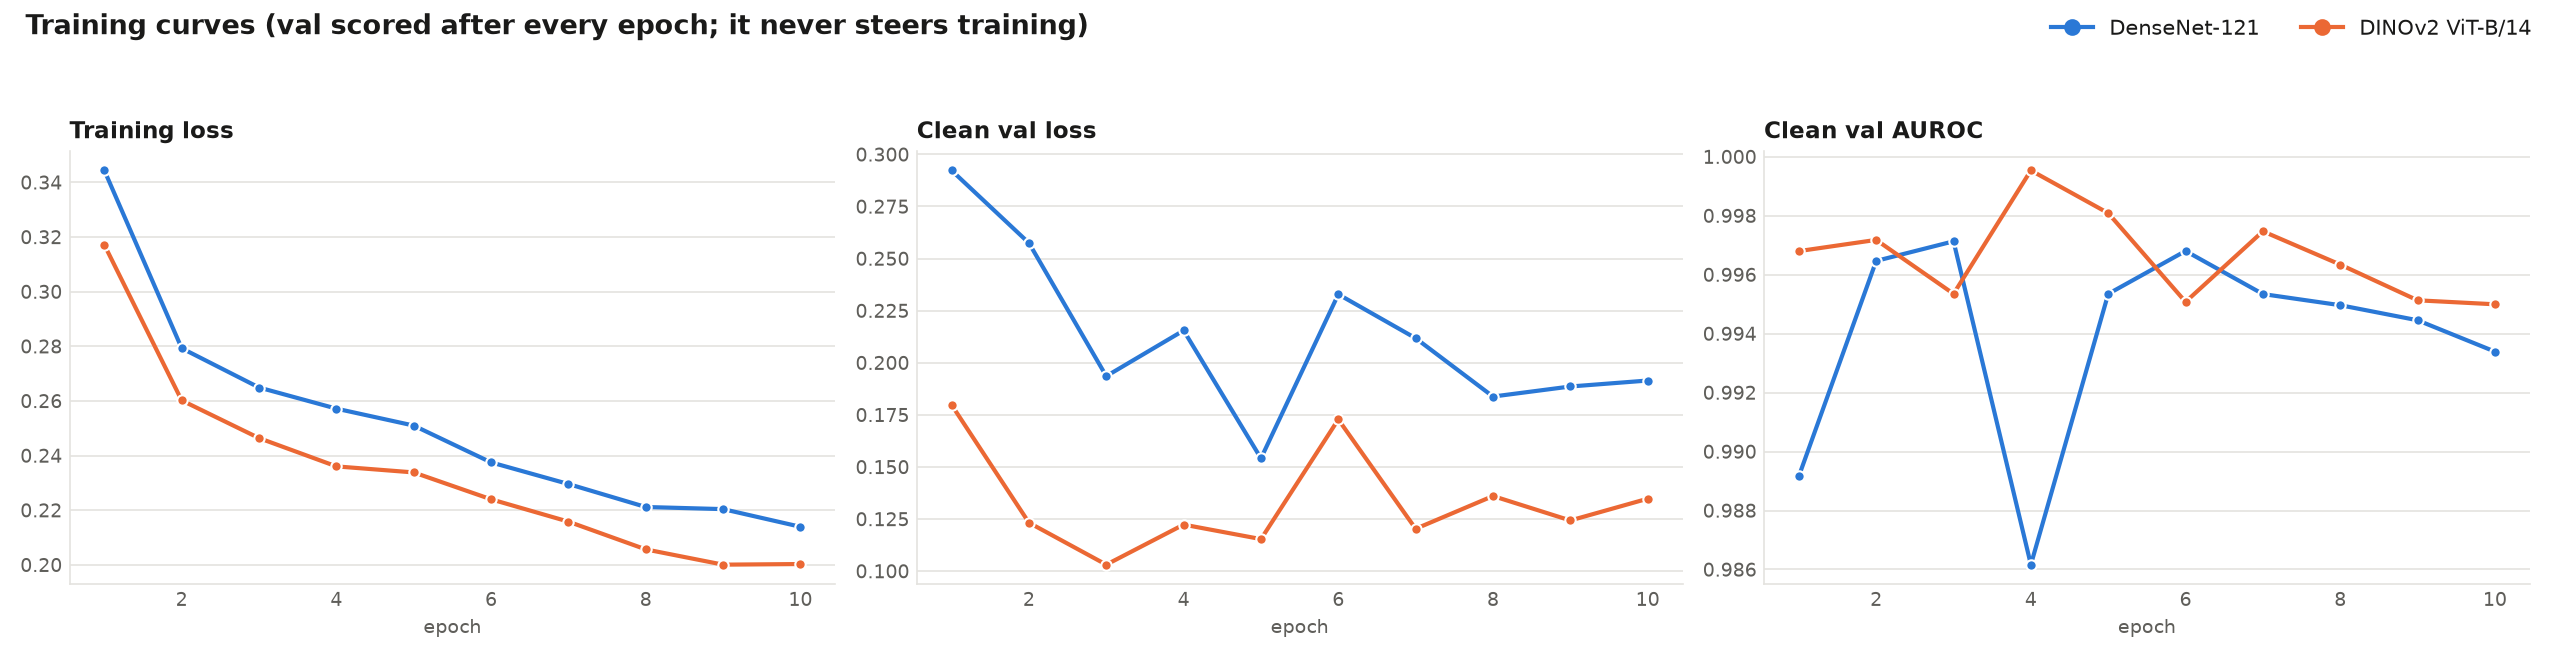

In [6]:
runs = {a: json.loads((RESULTS / a / "metrics.json").read_text()) for a in ARCHS if (RESULTS / a / "metrics.json").exists()}
rows = {}
for a, m in runs.items():
    rows[m["name"]] = {
        "AUROC (95% CI)": f"{m['auroc']:.4f} ({m['auroc_ci'][0]:.4f}-{m['auroc_ci'][1]:.4f})",
        "AP": f"{m['ap']:.3f}",
        "sensitivity (95% CI)": f"{m['sensitivity']:.3f} ({m['sensitivity_ci'][0]:.3f}-{m['sensitivity_ci'][1]:.3f})",
        "specificity": f"{m['specificity']:.3f}",
        "issues missed": f"{m['confusion']['fn']} of {m['n_issue']}",
        "false alarms": f"{m['confusion']['fp']} of {m['n_healthy']}",
        "threshold": f"{m['threshold']:.3f}",
        "AUROC, full test (leaky)": f"{m['full_test']['auroc']:.4f}",
        **{f"reaches YOLO: {c}": f"{v['share']:.0%} of {v['n']}" for c, v in m["passed_to_yolo"].items()}}
display(pd.DataFrame(rows))
report.write_all()                       # rebuilds comparison_report.txt and the graphs from the saved results
for f in report.FIGURES:
    display(Show(FIG / f, width=1000))

**Reading the graphs.** The ROC curves hug the top-left corner: near perfect, which with the source problem (section 4)
is a warning, not a win. Dips at the start of a precision-recall curve come from a few healthy-labelled photos the model
is very sure about (section 8: several are mislabelled). The calibration bins between 0.2 and 0.8 hold only a few dozen
photos, so their zigzag is mostly noise. The training-curve axes are zoomed in: AUROC moves within about 0.01.

## 7. Results per source

Within the clean test, the false-alarm rate on each healthy source and the catch rate on Roboflow. A model relying on
photo style would raise false alarms on the healthy sources that look most like Roboflow (close-up, cropped intraoral
photos such as `dentalai`). The real test of "disease, not source" needs issue photos from non-Roboflow sources that are
not copies of training photos; this split has none (they were all removed as copies, section 3).

In [7]:
per = []
for a, m in runs.items():
    p = pd.read_csv(RESULTS / a / "test_predictions.csv")
    p["flagged"] = p.p_issue >= m["threshold"]
    g = p.groupby(["dataset", TARGET]).agg(images=("flagged", "size"), flagged=("flagged", "mean"))
    per.append(g.flagged.rename(m["name"]))
per = pd.concat([g.images] + per, axis=1).reset_index()
per["what the share means"] = np.where(per[TARGET] == 1, "issues caught", "false alarms")
display(per.round(3))

,dataset,has_issue,images,DenseNet-121,DINOv2 ViT-B/14,what the share means
0,dentalai,0,94,0.074,0.053,false alarms
1,external_clean,0,14,0.071,0.071,false alarms
2,kaggle_oral,0,59,0.000,0.017,false alarms
3,mendeley_noncaries,0,472,0.002,0.000,false alarms
4,roboflow_oral,1,178,0.949,0.944,issues caught
5,zenodo,0,324,0.006,0.006,false alarms


## 8. Most confident mistakes

The healthy-labelled photos each model is most sure have an issue, and the issue photos it is most sure are healthy. Look
at them before blaming the model: several "healthy" labels come from Qwen or from a source folder name and are wrong
(e.g. a gum swelling with bleeding, labelled Normal). Report these to Daniel so the dataset can be fixed.

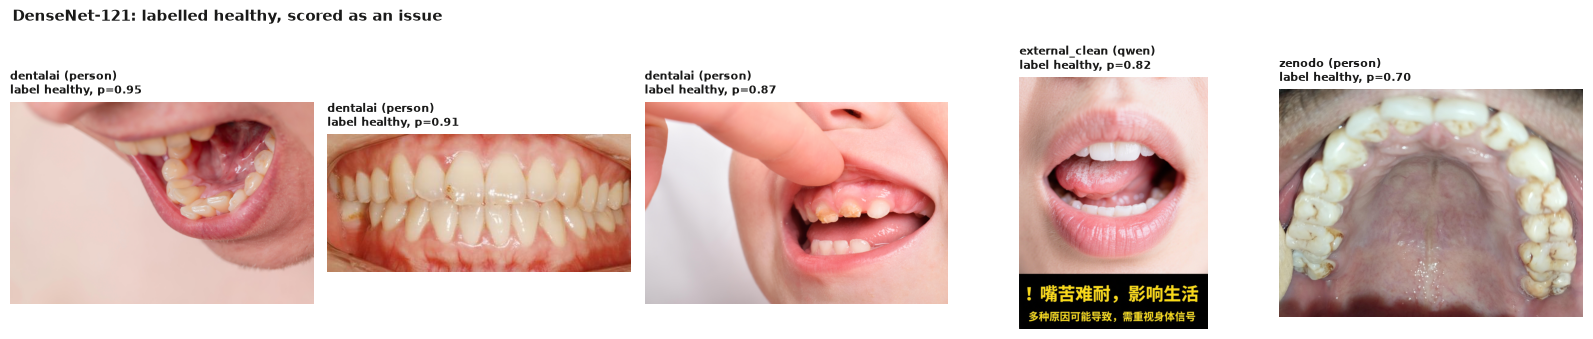

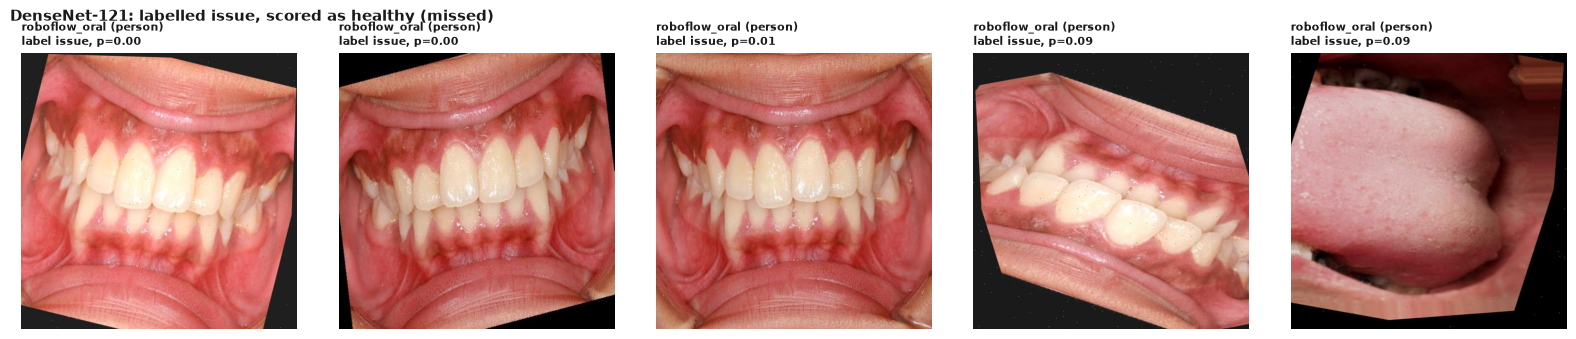

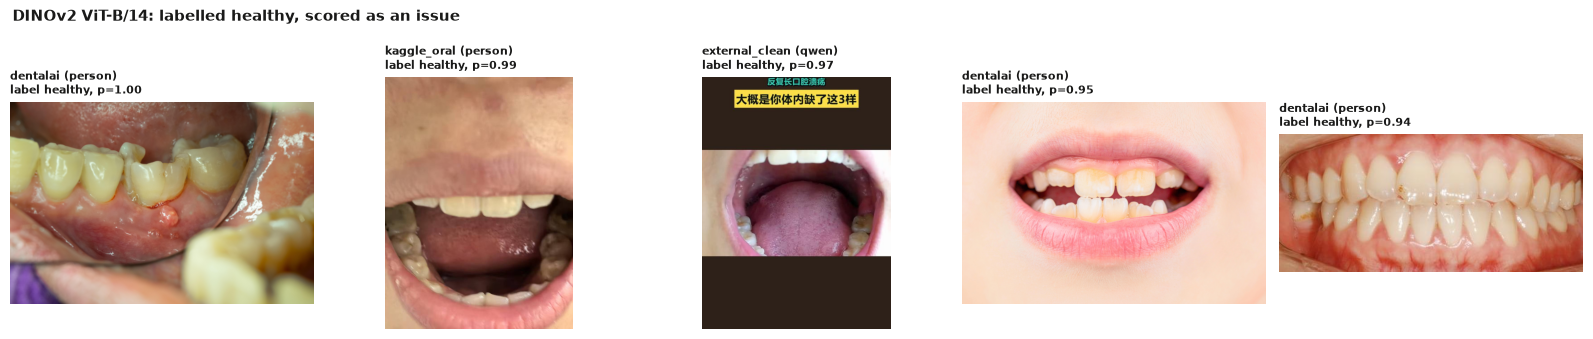

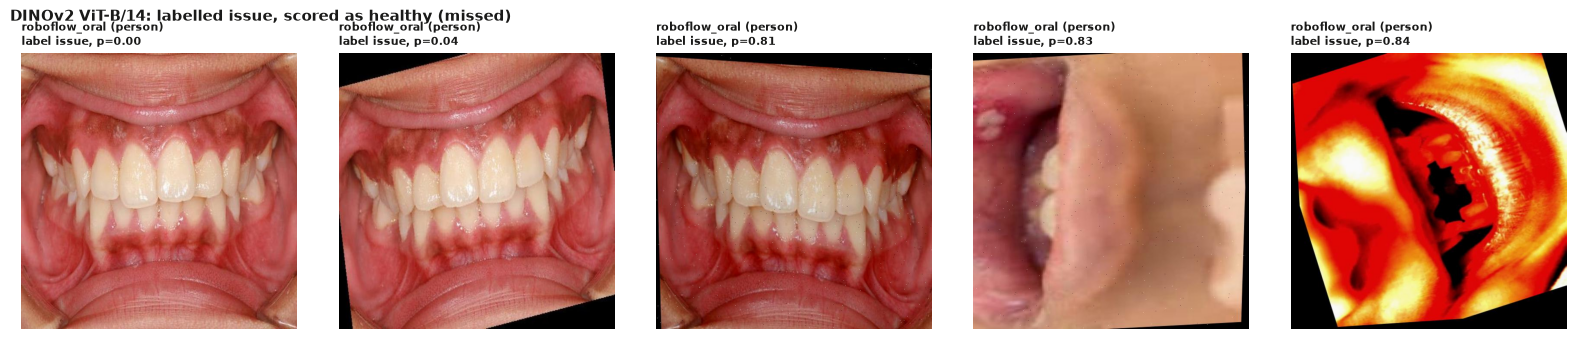

In [8]:
def show_row(frame, title):
    fig, ax = plt.subplots(1, len(frame), figsize=(3.2 * len(frame), 3.4))
    for a_, r in zip(np.atleast_1d(ax), frame.itertuples()):
        im = Image.open(DATA / r.image); im.draft("RGB", (400, 400))
        a_.imshow(im.convert("RGB")); a_.axis("off")
        a_.set_title(f"{r.dataset} ({r.label_by.split()[0]})\nlabel {'issue' if getattr(r, TARGET) else 'healthy'}, p={r.p_issue:.2f}", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold"); plt.tight_layout(); plt.show()

for a, m in runs.items():
    p = pd.read_csv(RESULTS / a / "test_predictions.csv")
    show_row(p[p[TARGET] == 0].nlargest(5, "p_issue"), f"{m['name']}: labelled healthy, scored as an issue")
    show_row(p[p[TARGET] == 1].nsmallest(5, "p_issue"), f"{m['name']}: labelled issue, scored as healthy (missed)")

## 9. Grad-CAM: where does each model look?

Red = the areas that pushed the "has an issue" score up most. Heat on teeth and gums is what we want; heat on lips,
background, borders or image corners would mean the model learned the photo style (section 4). For DenseNet the map comes
from its last convolutional features (7x7), for DINOv2 from its patch tokens (16x16 patches of 14 px), so the DINOv2
map is finer. Gradient maps on a ViT are noisier than on a CNN, so read the DINOv2 row as a hint, not proof.

Using cache found in C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


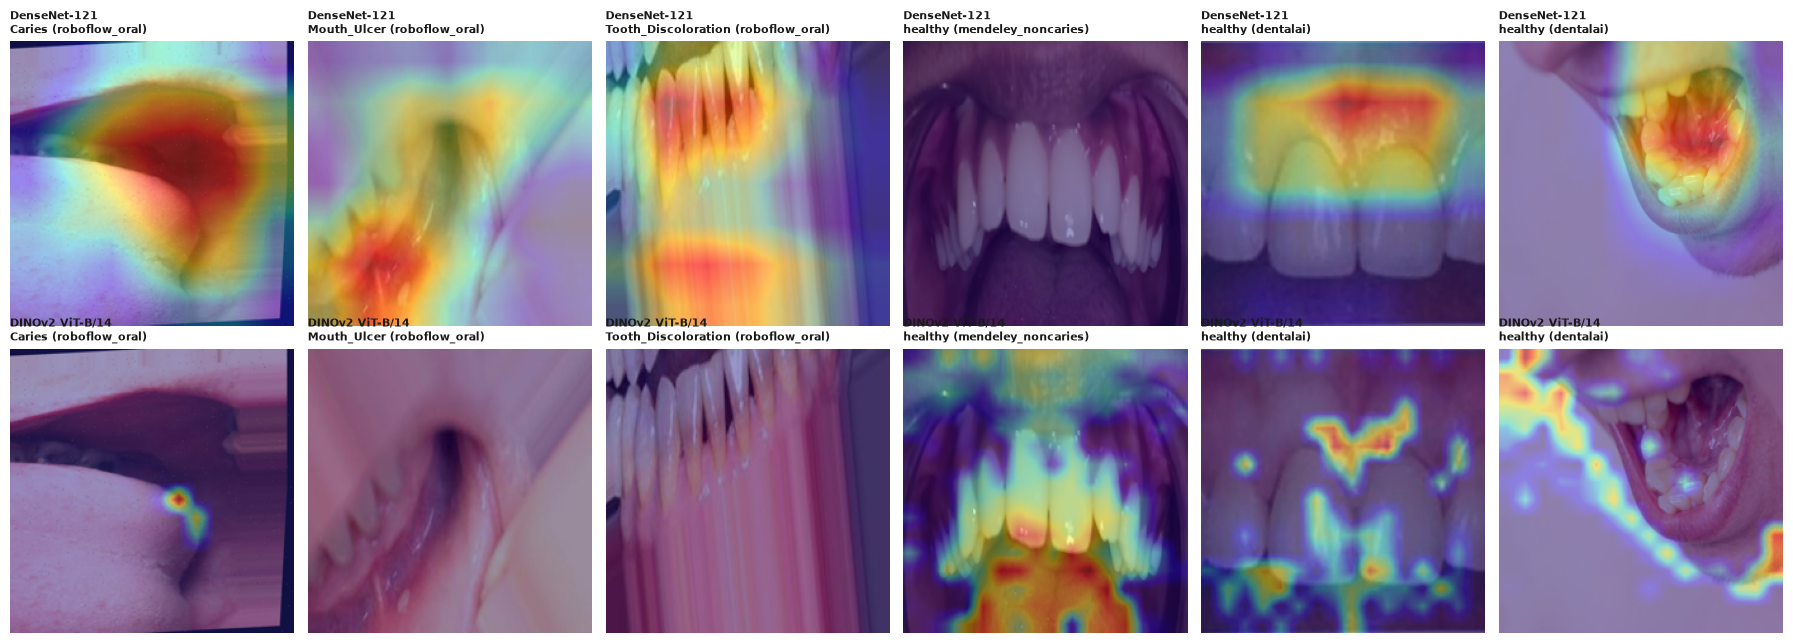

In [9]:
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def cam(net, x):
    if net.arch == "densenet121":
        feats = torch.relu(net.body.features(x))                       # B, C, 7, 7
        out = net.head(feats.mean((2, 3)))
        grad, = torch.autograd.grad(out[0, 0], feats)
        c = torch.relu((grad.mean((2, 3), keepdim=True) * feats).sum(1))[0]
    else:
        t = net.body.forward_features(x)
        tok = t["x_norm_patchtokens"]                                  # B, 256, D
        out = net.head(torch.cat([t["x_norm_clstoken"], tok.mean(1)], 1))
        grad, = torch.autograd.grad(out[0, 0], tok)
        s = int(tok.shape[1] ** 0.5)
        c = torch.relu((grad.mean(1, keepdim=True) * tok).sum(-1))[0].reshape(s, s)
    c = (c - c.min()) / (c.max() - c.min() + 1e-8)
    return c.detach().cpu().numpy()

p0 = pd.read_csv(RESULTS / "densenet121" / "test_predictions.csv")
pick = pd.concat([p0[p0[c] == 1].sample(1, random_state=1) for c in ["Caries", "Mouth_Ulcer", "Tooth_Discoloration"]]
                 + [p0[(p0[TARGET] == 0) & (p0.dataset == d)].sample(1, random_state=1) for d in ["mendeley_noncaries", "dentalai"]]
                 + [p0[p0[TARGET] == 0].nlargest(1, "p_issue")])
fig, ax = plt.subplots(len(runs), len(pick), figsize=(3 * len(pick), 3.2 * len(runs)), squeeze=False)
for i, (a, m) in enumerate(runs.items()):
    ck, nets, _ = multilabel.load_model(RESULTS / a / "model.pt", DEV)
    tf = multilabel.eval_tf(ck["img_size"])
    for j, r in enumerate(pick.itertuples()):
        im = Image.open(DATA / r.image).convert("RGB").resize((ck["img_size"], ck["img_size"]))
        c = cam(nets[0], tf(im).unsqueeze(0).to(DEV))
        ax[i, j].imshow(im); ax[i, j].imshow(np.array(Image.fromarray(np.uint8(c * 255)).resize(im.size, Image.BILINEAR)),
                                             cmap="jet", alpha=0.4)
        lab = ", ".join(k for k in CONDITIONS if getattr(r, k)) or "healthy"
        ax[i, j].set_title(f"{m['name']}\n{lab} ({r.dataset})", fontsize=8); ax[i, j].axis("off")
    del nets; torch.cuda.empty_cache()
plt.tight_layout(); plt.show()

## 10. Experiment log and decision

In [10]:
log = pd.DataFrame([{"model": m["name"], "epochs": m["settings"]["epochs"], "lr": m["settings"]["lr"], "img": m["settings"]["img"],
                     "train images": m["n_train"], "clean test AUROC": round(m["auroc"], 4), "AP": round(m["ap"], 3),
                     "sensitivity": round(m["sensitivity"], 3), "specificity": round(m["specificity"], 3),
                     "full-test AUROC": round(m["full_test"]["auroc"], 4)} for m in runs.values()])
display(log)

,model,epochs,lr,img,train images,clean test AUROC,AP,sensitivity,specificity,full-test AUROC
0,DenseNet-121,10,0.00010,224,31279,0.9953,0.974,0.949,0.989,0.9959
1,DINOv2 ViT-B/14,10,0.00002,224,31279,0.9925,0.894,0.944,0.991,0.9926


| Run | What changed | Why | Result (clean test) | Notes |
|---|---|---|---|---|
| gate v1 | DenseNet-121 vs DINOv2 ViT-B/14, 10 epochs, threshold catches 95% of clean-val issues | first binary gate on oral_dataset | see the table above | clean test is one source per class (section 4) |
| | | | | |

**Decision (fill in, then copy to `docs/decisions.md`):** which model is the gate, and why. Points to weigh: AUROC and
sensitivity are within each other's confidence intervals; DenseNet is about 10x smaller and faster (matters for a phone
or a free-tier server); DINOv2's probabilities are better calibrated; Grad-CAM (section 9) for which looks at the mouth.